# EDA SECOP II > Procesos

Este notebook analiza los procesos de contratación de SECOP II correspondientes al periodo seleccionado. Se revisa la calidad de los datos, su distribución territorial, las modalidades de contratación y los valores económicos.

## 1. Configuración

Se define el periodo de análisis y el territorio que se desea consultar. También se establece la conexión con MongoDB.

In [1]:
import os
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from pymongo import MongoClient

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

# Fuente fija. Solo se configuran año, mes y recorte territorial.
FUENTE = "procesos"
ANIO = 2026
MES = 9
TERRITORIO = "nacional"  # "nacional" o "bogota"
MONGO_DB = "secop"

cfg = {
    "nombre": "SECOP II Procesos de Contratación",
    "dataset_id": "p6dx-8zbt",
    "fecha": "fecha_de_publicacion_del",
    "pk": "id_del_proceso",
    "pk_fila": "socrata_id",
    "coleccion": "procesos_filas_api",
    "valor": "precio_base",
    "valor_alt": "valor_total_adjudicacion",
    "depto": "departamento_entidad",
    "muni": "ciudad_entidad",
    "entidad": "entidad",
    "proveedor": "nombre_del_proveedor",
    "modalidad": "modalidad_de_contratacion",
}

inicio = date(ANIO, MES, 1)
fin = date(ANIO + 1, 1, 1) if MES == 12 else date(ANIO, MES + 1, 1)
START_DATE = inicio.isoformat()
END_DATE = fin.isoformat()
PERIODO = f"{ANIO:04d}-{MES:02d}"

NB_DIR = Path("/home/jovyan/work/spark-apps/notebooks")
if not NB_DIR.exists():
    NB_DIR = Path.cwd()
SALIDAS = NB_DIR / "salidas" / PERIODO / FUENTE
FIGURAS = SALIDAS / "figuras"
SALIDAS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)


def guardar_fig(nombre):
    plt.tight_layout()
    plt.savefig(FIGURAS / nombre, dpi=120, bbox_inches="tight")
    print("Figura:", nombre)


def nulos_o_vacios(s):
    if s.dtype == object or str(s.dtype) == "string":
        txt = s.astype(str).str.strip()
        return s.isna() | txt.eq("") | txt.str.lower().isin(["nan", "none", "null"])
    return s.isna()


def es_bogota(serie):
    return serie.astype(str).str.lower().str.contains("bogot|distrito capital", regex=True, na=False)


uri = os.environ.get("MONGO_URI")
if not uri:
    raise RuntimeError("Falta MONGO_URI en el entorno del contenedor.")
client = MongoClient(uri, serverSelectionTimeoutMS=10000)
client.admin.command("ping")
db = client[MONGO_DB]
print("MongoDB: OK |", cfg["nombre"], "|", PERIODO, "|", TERRITORIO)
print("Colección:", cfg["coleccion"])


MongoDB: OK | SECOP II Procesos de Contratación | 2026-09 | nacional
Colección: procesos_filas_api


## 2. Carga

Se consultan los registros almacenados en MongoDB y se seleccionan los correspondientes al periodo de análisis.

Para las estadísticas generales, se considera una sola fila por proceso de contratación, evitando contar varias veces un mismo proceso.

In [2]:
col = db[cfg["coleccion"]]
if cfg["coleccion"] not in db.list_collection_names():
    raise RuntimeError(
        f"No existe {cfg['coleccion']}. Ejecute 01_ingesta_procesos.ipynb."
    )

n_raw = db["procesos_raw"].count_documents({"_periodo": PERIODO}) if "procesos_raw" in db.list_collection_names() else 0
filas = pd.DataFrame(list(col.find({"_periodo": PERIODO})))
if filas.empty:
    raise RuntimeError(
        f"No hay documentos de {PERIODO} en {cfg['coleccion']}. Ejecute 01_ingesta_procesos.ipynb."
    )

filas["fecha_ref"] = pd.to_datetime(filas.get(cfg["fecha"]), errors="coerce")
filas = filas[(filas["fecha_ref"] >= START_DATE) & (filas["fecha_ref"] < END_DATE)].copy()
n_sid = filas[cfg["pk_fila"]].nunique(dropna=True) if cfg["pk_fila"] in filas.columns else 0
n_proc = filas[cfg["pk"]].nunique(dropna=True) if cfg["pk"] in filas.columns else 0

# Descriptivos a grano proceso (una fila por id_del_proceso). Las filas API se conservan en `filas`.
df = filas.drop_duplicates(cfg["pk"], keep="first").copy()
df["_es_bogota"] = es_bogota(df[cfg["depto"]]) if cfg["depto"] in df.columns else False
n_nacional = len(df)
n_bta = int(df["_es_bogota"].sum())

if TERRITORIO.lower() == "bogota":
    df = df[df["_es_bogota"]].copy()
    print("Filtro: Bogotá / Distrito Capital")

print("Filas API:", f"{len(filas):,}".replace(",", "."), "| socrata_id:", f"{n_sid:,}".replace(",", "."))
print("Procesos (id_del_proceso):", f"{n_proc:,}".replace(",", "."), "| procesos_raw (sin tocar):", f"{n_raw:,}".replace(",", "."))
print("Nacional:", f"{n_nacional:,}".replace(",", "."), "| Bogotá (recorte):", f"{n_bta:,}".replace(",", "."))
print("Periodo real:", df["fecha_ref"].min(), "→", df["fecha_ref"].max())
print("Estas cifras de Bogotá no se comparan con el Portal de Transparencia.")
display(df.drop(columns=["_id"], errors="ignore").head(5))


Filas API: 158.830 | socrata_id: 158.830
Procesos (id_del_proceso): 146.947 | procesos_raw (sin tocar): 146.947
Nacional: 146.947 | Bogotá (recorte): 19.278
Periodo real: 2026-09-01 00:00:00 → 2026-09-30 00:00:00
Estas cifras de Bogotá no se comparan con el Portal de Transparencia.


,socrata_id,:id,_dataset_id,_fuente,_ingestion_ts,_nivel,_periodo,adjudicado,categorias_adicionales,ciudad_de_la_unidad_de,...,unidad_de_duracion,urlproceso,valor_total_adjudicacion,visualizaciones_del,fecha_adjudicacion,fecha_de_apertura_de_respuesta,fecha_de_apertura_efectiva,fecha_de_recepcion_de,fecha_ref,_es_bogota
0,row-mjib.jpa2-yfrj,row-mjib.jpa2-yfrj,p6dx-8zbt,procesos,2026-10-26 13:40:22.056,filas,2026-09,No,No definido,San Miguel,...,día(s),{'url': 'https://community.secop.gov.co/Public...,0,0,NaN,NaN,NaN,NaN,2026-09-09,False
1,row-8tdu_nuxd.dv9y,row-8tdu_nuxd.dv9y,p6dx-8zbt,procesos,2026-10-26 13:40:22.056,filas,2026-09,No,No definido,No Aplica,...,Mes(es),{'url': 'https://community.secop.gov.co/Public...,0,0,NaN,NaN,NaN,NaN,2026-09-29,False
2,row-qn7a~63qa-f8en,row-qn7a~63qa-f8en,p6dx-8zbt,procesos,2026-10-26 13:40:22.056,filas,2026-09,Si,No definido,Villavicencio,...,Mes(es),{'url': 'https://community.secop.gov.co/Public...,5000000,1,2026-10-07T00:00:00.000,2026-10-02T00:00:00.000,2026-10-02T00:00:00.000,2026-10-02T00:00:00.000,2026-09-29,False
3,row-b82m_fsz9-qxbu,row-b82m_fsz9-qxbu,p6dx-8zbt,procesos,2026-10-26 13:40:22.056,filas,2026-09,No,No definido,Medellín,...,día(s),{'url': 'https://community.secop.gov.co/Public...,0,0,NaN,NaN,NaN,NaN,2026-09-18,False
4,row-q7uw~gjh7-ctc2,row-q7uw~gjh7-ctc2,p6dx-8zbt,procesos,2026-10-26 13:40:22.056,filas,2026-09,No,No definido,Cartagena,...,Mes(es),{'url': 'https://community.secop.gov.co/Public...,0,0,NaN,NaN,NaN,NaN,2026-09-08,False


## 3. Calidad

Se revisan los valores faltantes, los registros duplicados, las fechas y los valores económicos para identificar posibles problemas en la información.

In [3]:
cols_clave = [cfg["pk"], cfg["fecha"], cfg["valor"], cfg["depto"], cfg["muni"],
              cfg["entidad"], cfg["proveedor"], cfg["modalidad"]]
if cfg["valor_alt"]:
    cols_clave.append(cfg["valor_alt"])

n = len(df)
n_pk = df[cfg["pk"]].nunique(dropna=True) if cfg["pk"] in df.columns else 0
valor = pd.to_numeric(df[cfg["valor"]], errors="coerce") if cfg["valor"] in df.columns else pd.Series(dtype=float)

resumen = pd.Series({
    "fuente": FUENTE,
    "dataset": cfg["dataset_id"],
    "filas": n,
    "pk_distintas": n_pk,
    "duplicados_pk": n - n_pk,
    "fecha_min": df["fecha_ref"].min(),
    "fecha_max": df["fecha_ref"].max(),
    "fechas_nulas": int(df["fecha_ref"].isna().sum()),
    "departamentos": df[cfg["depto"]].nunique(dropna=True) if cfg["depto"] in df.columns else 0,
    "municipios": df[cfg["muni"]].nunique(dropna=True) if cfg["muni"] in df.columns else 0,
    "entidades": df[cfg["entidad"]].nunique(dropna=True) if cfg["entidad"] in df.columns else 0,
    "proveedores": df[cfg["proveedor"]].nunique(dropna=True) if cfg["proveedor"] in df.columns else 0,
    "bogota": n_bta,
    "pct_bogota": round(100 * n_bta / n_nacional, 2) if n_nacional else 0,
    "valor_mediana": float(valor.median()) if valor.notna().any() else np.nan,
    "valor_p95": float(valor.quantile(0.95)) if valor.notna().any() else np.nan,
    "valor_max": float(valor.max()) if valor.notna().any() else np.nan,
    "valor_cero": int((valor == 0).sum()) if valor.notna().any() else 0,
    "valor_negativo": int((valor < 0).sum()) if valor.notna().any() else 0,
})
display(resumen.to_frame("valor"))
resumen.to_frame("valor").to_csv(SALIDAS / "resumen.csv")

nulos = []
for c in cols_clave:
    if c not in df.columns:
        nulos.append({"campo": c, "nulos_o_vacios": n, "pct": 100.0, "existe": False})
        continue
    nv = int(nulos_o_vacios(df[c]).sum())
    nulos.append({"campo": c, "nulos_o_vacios": nv, "pct": round(100 * nv / n, 2) if n else 0, "existe": True})
tab_nulos = pd.DataFrame(nulos)
display(tab_nulos)
tab_nulos.to_csv(SALIDAS / "nulos.csv", index=False)
print("Duplicados de", cfg["pk"] + ":", n - n_pk)


,valor
fuente,procesos
dataset,p6dx-8zbt
filas,146947
pk_distintas,146947
duplicados_pk,0
fecha_min,2026-09-01 00:00:00
fecha_max,2026-09-30 00:00:00
fechas_nulas,0
departamentos,34
municipios,929


,campo,nulos_o_vacios,pct,existe
0,id_del_proceso,0,0.0,True
1,fecha_de_publicacion_del,0,0.0,True
2,precio_base,0,0.0,True
3,departamento_entidad,0,0.0,True
4,ciudad_entidad,0,0.0,True
5,entidad,0,0.0,True
6,nombre_del_proveedor,0,0.0,True
7,modalidad_de_contratacion,0,0.0,True
8,valor_total_adjudicacion,0,0.0,True


Duplicados de id_del_proceso: 0


## 4. Territorio, modalidades, entidades y proveedores

Se analiza la cantidad de procesos por departamento, municipio, modalidad de contratación, entidad y proveedor.

In [4]:
depto = df[cfg["depto"]].fillna("No Definido").astype(str).value_counts().head(15)
muni = df[cfg["muni"]].fillna("No Definido").astype(str).value_counts().head(15)
mod = df[cfg["modalidad"]].fillna("No Definido").astype(str).value_counts().head(15) if cfg["modalidad"] in df.columns else pd.Series(dtype=int)
ent = df[cfg["entidad"]].fillna("No Definido").astype(str).value_counts().head(15)
prv = df[cfg["proveedor"]].fillna("No Definido").astype(str).value_counts().head(15)

print("Departamentos")
display(depto.to_frame("n"))
print("Municipios")
display(muni.to_frame("n"))
print("Modalidades")
display(mod.to_frame("n"))
print("Entidades")
display(ent.to_frame("n"))
print("Proveedores")
display(prv.to_frame("n"))

depto.rename("n").to_csv(SALIDAS / "departamentos.csv")
muni.rename("n").to_csv(SALIDAS / "municipios.csv")
mod.rename("n").to_csv(SALIDAS / "modalidades.csv")
ent.rename("n").to_csv(SALIDAS / "entidades.csv")
prv.rename("n").to_csv(SALIDAS / "proveedores.csv")


Departamentos


,n
departamento_entidad,
Distrito Capital de Bogotá,19278
Antioquia,18627
No Definido,12180
Valle del Cauca,11114
Santander,7539
Cundinamarca,7004
Bolívar,6794
Magdalena,5463
Boyacá,4984


Municipios


,n
ciudad_entidad,
No Definido,31021
Bogotá,9449
Medellín,8833
Cali,6074
Cartagena,3942
Pereira,3525
Bucaramanga,3219
Armenia,2936
Villavicencio,2526


Modalidades


,n
modalidad_de_contratacion,
Contratación régimen especial,67851
Contratación directa,65473
Mínima cuantía,4393
Selección Abreviada de Menor Cuantía,2853
Solicitud de información a los Proveedores,2455
Selección abreviada subasta inversa,1313
Contratación régimen especial (con ofertas),832
Contratación Directa (con ofertas),753
Concurso de méritos abierto,458


Entidades


,n
entidad,
UNIVERSIDAD NACIONAL DE COLOMBIA,2745
ALCALDÍA DEL DISTRITO TURÍSTICO Y CULTURAL DE CARTAGENA DE INDIAS,2348
METROPARQUES,2217
INSTITUCIÓN UNIVERSITARIA ITM,2073
MUNICIPIO DE PEREIRA- OFICIAL,1669
INSTITUTO DE DEPORTES Y RECREACION DE MEDELLIN,1632
(Secretaría Distrital de Integración Social),1518
MUNICIPIO DE ARMENIA QUINDIO,1157
MUNICIPIO DE BUCARAMANGA,1077


Proveedores


,n
nombre_del_proveedor,
No Definido,126078
Aseguradora Solidaria de Colombia Entidad Cooperativa.,92
LA PREVISORA S.A. COMPAÑÍA DE SEGUROS,51
MERCASALUD SUR SAS,46
E.S.E HOSPITAL MUNICIPAL SAN ANTONIO DE TIMANA,38
HEALTH TEAM SAS,35
COMEDICA S.A.S.,28
SUMINISTROS Y DOTACIONES COLOMBIA S.A.,27
ESE HOSPITAL IVAN RESTREPO GOMEZ DE URRAO,25


## 5. Gráficos

Se presentan gráficos que permiten identificar las principales características y distribuciones de los procesos de contratación.

Figura: departamentos.png


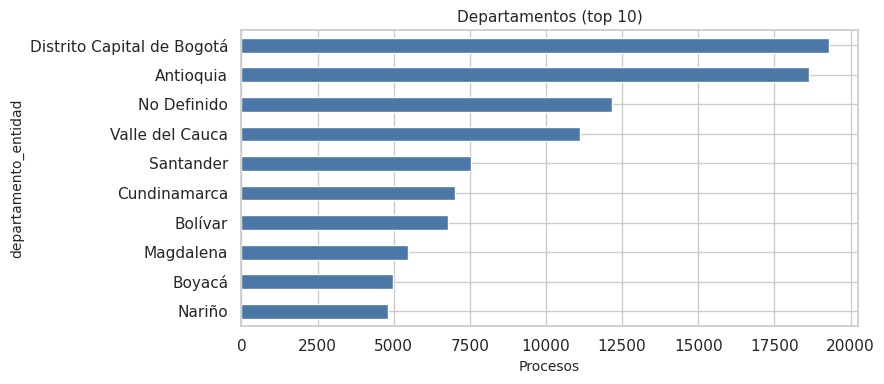

Figura: modalidades.png


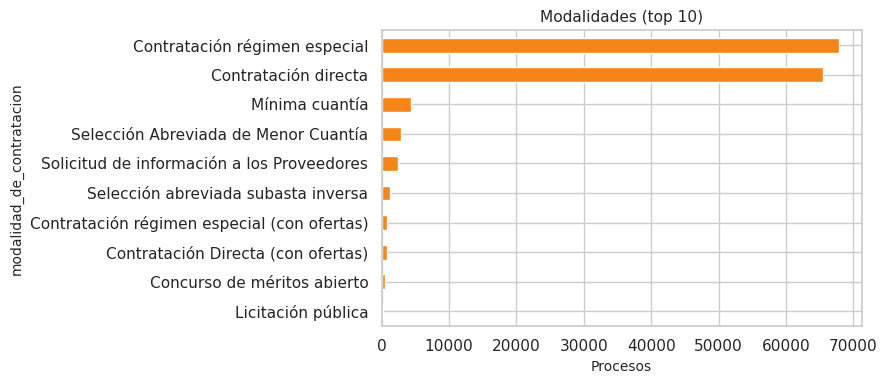

Figura: diario.png


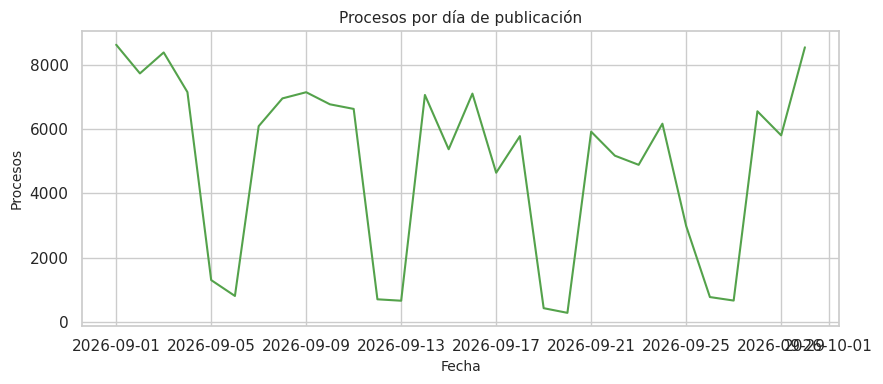

Figura: valor.png


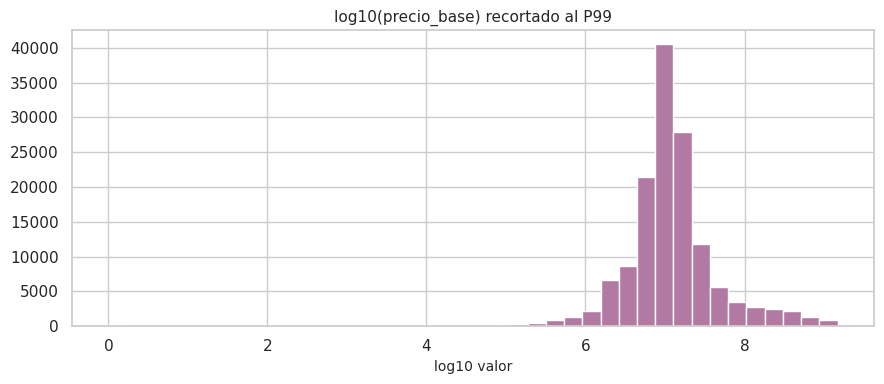

In [5]:
fig, ax = plt.subplots()
depto.head(10).sort_values().plot(kind="barh", ax=ax, color="#4C78A8")
ax.set_title("Departamentos (top 10)")
ax.set_xlabel("Procesos")
guardar_fig("departamentos.png")
plt.show()

fig, ax = plt.subplots()
mod.head(10).sort_values().plot(kind="barh", ax=ax, color="#F58518")
ax.set_title("Modalidades (top 10)")
ax.set_xlabel("Procesos")
guardar_fig("modalidades.png")
plt.show()

serie = df.dropna(subset=["fecha_ref"]).groupby(df["fecha_ref"].dt.date).size()
fig, ax = plt.subplots()
serie.plot(ax=ax, color="#54A24B")
ax.set_title("Procesos por día de publicación")
ax.set_xlabel("Fecha")
ax.set_ylabel("Procesos")
guardar_fig("diario.png")
plt.show()

val = valor.dropna()
val = val[(val > 0) & (val < val.quantile(0.99))] if not val.empty else val
if not val.empty:
    fig, ax = plt.subplots()
    ax.hist(np.log10(val), bins=40, color="#B279A2")
    ax.set_title(f"log10({cfg['valor']}) recortado al P99")
    ax.set_xlabel("log10 valor")
    guardar_fig("valor.png")
    plt.show()


## 6. Bogotá (recorte, no comparación con el Portal)

Se examinan los procesos asociados a Bogotá para conocer sus principales características.

In [6]:
tab_bta = pd.DataFrame([{
    "fuente": cfg["nombre"],
    "nacional": n_nacional,
    "bogota": n_bta,
    "pct_bogota": round(100 * n_bta / n_nacional, 2) if n_nacional else 0,
    "etiquetas": ", ".join(sorted(df.loc[df["_es_bogota"], cfg["depto"]].dropna().astype(str).unique())[:8]) if TERRITORIO.lower() != "bogota" else "(filtro ya aplicado)",
}])
display(tab_bta)
tab_bta.to_csv(SALIDAS / "bogota.csv", index=False)
print("Recorte territorial de procesos. No se compara con indicadores de contratos del Portal.")


,fuente,nacional,bogota,pct_bogota,etiquetas
0,SECOP II Procesos de Contratación,146947,19278,13.12,Distrito Capital de Bogotá


Recorte territorial de procesos. No se compara con indicadores de contratos del Portal.


## 7. Duplicados de `id_del_proceso`

Se identifican los procesos que aparecen más de una vez en los datos originales y se revisan las diferencias entre sus registros.

In [7]:
CAMPOS_CMP = [
    "id_del_proceso",
    "estado_del_procedimiento",
    "fecha_de_publicacion_del",
    "fecha_de_ultima_publicaci",
    "modalidad_de_contratacion",
    "entidad",
    "departamento_entidad",
    "ciudad_entidad",
    "precio_base",
    "valor_total_adjudicacion",
    "adjudicado",
    "nombre_del_proveedor",
]
campos = [c for c in CAMPOS_CMP if c in filas.columns]
api = filas[campos].copy()
for c in ("precio_base", "valor_total_adjudicacion"):
    if c in api.columns:
        api[c] = pd.to_numeric(api[c], errors="coerce")

vc = api[cfg["pk"]].value_counts()
dups_ids = vc[vc > 1]
n_filas_dup = int(dups_ids.sum())
n_ids_dup = int(len(dups_ids))
n_filas_extra = n_filas_dup - n_ids_dup

print("Filas API:", f"{len(api):,}".replace(",", "."))
print("PK distintas API:", f"{api[cfg['pk']].nunique():,}".replace(",", "."))
print("PK repetidas:", f"{n_ids_dup:,}".replace(",", "."))
print("Filas extra (repeticiones):", f"{n_filas_extra:,}".replace(",", "."))
print("Veces por PK (repetidas): min", int(dups_ids.min()) if n_ids_dup else 0,
      "mediana", float(dups_ids.median()) if n_ids_dup else 0,
      "máx", int(dups_ids.max()) if n_ids_dup else 0)

campos_var = [c for c in campos if c != cfg["pk"]]
if n_ids_dup:
    g = api[api[cfg["pk"]].isin(dups_ids.index)].groupby(cfg["pk"])
    var_por_campo = {c: int((g[c].nunique(dropna=False) > 1).sum()) for c in campos_var}
    n_identicos = int((g[campos_var].nunique(dropna=False).max(axis=1) <= 1).sum())
    n_distintos = n_ids_dup - n_identicos
    tab_var = pd.Series(var_por_campo, name="pk_con_diferencia").sort_values(ascending=False)
    print("PK repetidas idénticas en campos comparados:", f"{n_identicos:,}".replace(",", "."))
    print("PK repetidas con alguna diferencia:", f"{n_distintos:,}".replace(",", "."))
    display(tab_var.to_frame())
    tab_var.to_csv(SALIDAS / "duplicados_campos_variables.csv")

    nuniq = g[campos_var].nunique(dropna=False).max(axis=1)
    ident_ids = nuniq[nuniq <= 1].index.tolist()
    diff_ids = nuniq[nuniq > 1].index.tolist()
    var_prov_val = [c for c in ["nombre_del_proveedor", "valor_total_adjudicacion"] if c in campos]
    n_195 = int((g[var_prov_val].nunique(dropna=False).max(axis=1) > 1).sum()) if var_prov_val else 0
    print("Con diferencia en proveedor o valor:", n_195)

    def mostrar_ejemplo(pid, titulo):
        print("\n" + titulo, pid)
        display(api[api[cfg["pk"]] == pid][campos].reset_index(drop=True))

    if ident_ids:
        mostrar_ejemplo(ident_ids[0], "Ejemplo idéntico")
    if diff_ids:
        mostrar_ejemplo(diff_ids[0], "Ejemplo con diferencias")
else:
    n_identicos = n_distintos = n_195 = 0


Filas API: 158.830
PK distintas API: 146.947
PK repetidas: 1.561
Filas extra (repeticiones): 11.883
Veces por PK (repetidas): min 2 mediana 2.0 máx 8405
PK repetidas idénticas en campos comparados: 1.366
PK repetidas con alguna diferencia: 195


,pk_con_diferencia
valor_total_adjudicacion,192
nombre_del_proveedor,98
estado_del_procedimiento,0
fecha_de_publicacion_del,0
fecha_de_ultima_publicaci,0
modalidad_de_contratacion,0
entidad,0
departamento_entidad,0
ciudad_entidad,0
precio_base,0


Con diferencia en proveedor o valor: 195

Ejemplo idéntico CO1.REQ.10322141


,id_del_proceso,estado_del_procedimiento,fecha_de_publicacion_del,fecha_de_ultima_publicaci,modalidad_de_contratacion,entidad,departamento_entidad,ciudad_entidad,precio_base,valor_total_adjudicacion,adjudicado,nombre_del_proveedor
0,CO1.REQ.10322141,Evaluación,2026-09-10T00:00:00.000,2026-09-10T00:00:00.000,Selección abreviada subasta inversa,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,291625464,0,No,No Definido
1,CO1.REQ.10322141,Evaluación,2026-09-10T00:00:00.000,2026-09-10T00:00:00.000,Selección abreviada subasta inversa,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,291625464,0,No,No Definido
2,CO1.REQ.10322141,Evaluación,2026-09-10T00:00:00.000,2026-09-10T00:00:00.000,Selección abreviada subasta inversa,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,291625464,0,No,No Definido
3,CO1.REQ.10322141,Evaluación,2026-09-10T00:00:00.000,2026-09-10T00:00:00.000,Selección abreviada subasta inversa,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,291625464,0,No,No Definido
4,CO1.REQ.10322141,Evaluación,2026-09-10T00:00:00.000,2026-09-10T00:00:00.000,Selección abreviada subasta inversa,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,291625464,0,No,No Definido
5,CO1.REQ.10322141,Evaluación,2026-09-10T00:00:00.000,2026-09-10T00:00:00.000,Selección abreviada subasta inversa,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,291625464,0,No,No Definido
6,CO1.REQ.10322141,Evaluación,2026-09-10T00:00:00.000,2026-09-10T00:00:00.000,Selección abreviada subasta inversa,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,291625464,0,No,No Definido
7,CO1.REQ.10322141,Evaluación,2026-09-10T00:00:00.000,2026-09-10T00:00:00.000,Selección abreviada subasta inversa,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,291625464,0,No,No Definido
8,CO1.REQ.10322141,Evaluación,2026-09-10T00:00:00.000,2026-09-10T00:00:00.000,Selección abreviada subasta inversa,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,291625464,0,No,No Definido



Ejemplo con diferencias CO1.REQ.10456528


,id_del_proceso,estado_del_procedimiento,fecha_de_publicacion_del,fecha_de_ultima_publicaci,modalidad_de_contratacion,entidad,departamento_entidad,ciudad_entidad,precio_base,valor_total_adjudicacion,adjudicado,nombre_del_proveedor
0,CO1.REQ.10456528,Seleccionado,2026-09-08T00:00:00.000,2026-09-08T00:00:00.000,Mínima cuantía,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,78901413,7633000,Si,OFFICENEED S.A.S
1,CO1.REQ.10456528,Seleccionado,2026-09-08T00:00:00.000,2026-09-08T00:00:00.000,Mínima cuantía,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,78901413,7633000,Si,OFFICENEED S.A.S
2,CO1.REQ.10456528,Seleccionado,2026-09-08T00:00:00.000,2026-09-08T00:00:00.000,Mínima cuantía,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,78901413,7633000,Si,OFFICENEED S.A.S
3,CO1.REQ.10456528,Seleccionado,2026-09-08T00:00:00.000,2026-09-08T00:00:00.000,Mínima cuantía,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,78901413,7633000,Si,OFFICENEED S.A.S
4,CO1.REQ.10456528,Seleccionado,2026-09-08T00:00:00.000,2026-09-08T00:00:00.000,Mínima cuantía,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,78901413,60252000,Si,MANUEL ALEJANDRO RAMOS LOMAS
5,CO1.REQ.10456528,Seleccionado,2026-09-08T00:00:00.000,2026-09-08T00:00:00.000,Mínima cuantía,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,78901413,60252000,Si,MANUEL ALEJANDRO RAMOS LOMAS
6,CO1.REQ.10456528,Seleccionado,2026-09-08T00:00:00.000,2026-09-08T00:00:00.000,Mínima cuantía,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,78901413,60252000,Si,MANUEL ALEJANDRO RAMOS LOMAS
7,CO1.REQ.10456528,Seleccionado,2026-09-08T00:00:00.000,2026-09-08T00:00:00.000,Mínima cuantía,GOBERNACIÓN DEL CAUCA,Cauca,Popayán,78901413,60252000,Si,MANUEL ALEJANDRO RAMOS LOMAS


## 8. Territorio, ceros y extremos

Se revisa la distribución territorial y se identifican valores iguales a cero o especialmente elevados que requieren atención.

In [8]:
depto_all = df[cfg["depto"]].fillna("No Definido").astype(str)
tab_depto = depto_all.value_counts().rename("n").to_frame()
tab_depto["pct"] = (100 * tab_depto["n"] / len(df)).round(2)
print("Categorías territoriales:", len(tab_depto))
display(tab_depto)
tab_depto.to_csv(SALIDAS / "territorios.csv")

nd = df[depto_all.eq("No Definido")].copy()
print("No Definido:", f"{len(nd):,}".replace(",", "."))
if not nd.empty:
    print("Ciudad en No Definido:")
    display(nd[cfg["muni"]].fillna("No Definido").astype(str).value_counts().head(8).to_frame("n"))
    print("Modalidad en No Definido:")
    display(nd[cfg["modalidad"]].fillna("No Definido").astype(str).value_counts().head(8).to_frame("n"))
    print("Ejemplo No Definido:")
    display(nd[[cfg["pk"], cfg["entidad"], cfg["muni"], cfg["modalidad"], cfg["valor"]]].head(5))

ceros = df[valor.eq(0)].copy()
print("precio_base = 0:", f"{len(ceros):,}".replace(",", "."))
if not ceros.empty:
    if "adjudicado" in ceros.columns:
        print("Adjudicado cuando precio_base=0:")
        display(ceros["adjudicado"].astype(str).value_counts().head(8).to_frame("n"))
    if "estado_del_procedimiento" in ceros.columns:
        print("Estado cuando precio_base=0:")
        display(ceros["estado_del_procedimiento"].astype(str).value_counts().head(8).to_frame("n"))
    print("Modalidad cuando precio_base=0:")
    display(ceros[cfg["modalidad"]].astype(str).value_counts().head(8).to_frame("n"))
    display(ceros[[cfg["pk"], cfg["entidad"], cfg["modalidad"], cfg["valor"]]].head(5))

p99 = float(valor.quantile(0.99)) if valor.notna().any() else 0
extremos = df[valor > 1e12].copy()
print("P99 precio_base:", f"{p99:,.0f}".replace(",", "."))
print("precio_base > 1e12:", len(extremos))
top = df.assign(_v=valor).nlargest(8, "_v")
display(top[[cfg["pk"], cfg["entidad"], cfg["depto"], cfg["modalidad"], cfg["valor"]]])
top[[cfg["pk"], cfg["entidad"], cfg["depto"], cfg["modalidad"], cfg["valor"]]].to_csv(
    SALIDAS / "valores_extremos.csv", index=False
)
if not nd.empty:
    nd[[cfg["pk"], cfg["entidad"], cfg["muni"], cfg["modalidad"], cfg["valor"]]].head(20).to_csv(
        SALIDAS / "no_definido_ejemplos.csv", index=False
    )


Categorías territoriales: 34


,n,pct
departamento_entidad,,
Distrito Capital de Bogotá,19278,13.12
Antioquia,18627,12.68
No Definido,12180,8.29
Valle del Cauca,11114,7.56
Santander,7539,5.13
Cundinamarca,7004,4.77
Bolívar,6794,4.62
Magdalena,5463,3.72
Boyacá,4984,3.39


No Definido: 12.180
Ciudad en No Definido:


,n
ciudad_entidad,
No Definido,12180


Modalidad en No Definido:


,n
modalidad_de_contratacion,
Contratación régimen especial,10825
Contratación directa,1082
Mínima cuantía,95
Contratación régimen especial (con ofertas),67
Selección Abreviada de Menor Cuantía,49
Solicitud de información a los Proveedores,22
Selección abreviada subasta inversa,21
Contratación Directa (con ofertas),6


... (7 outputs left out)

,n
modalidad_de_contratacion,
Solicitud de información a los Proveedores,2455
Contratación régimen especial,1226
Contratación directa,456
Concurso de méritos abierto,16
Subasta de prueba,14
Contratación régimen especial (con ofertas),9
Selección Abreviada de Menor Cuantía,6
Licitación pública,5


,id_del_proceso,entidad,modalidad_de_contratacion,precio_base
35,CO1.REQ.11037082,CORPORACION AUTONOMA REGIONAL DE CUNDINAMARCA ...,Contratación directa,0
37,CO1.REQ.11088049,UNIDAD ADMINISTRATIVA ESPECIAL JUNTA CENTRAL D...,Solicitud de información a los Proveedores,0
214,CO1.REQ.11066124,LA CORPORACION COLOMBIANA DE INVESTIGACION AGR...,Contratación régimen especial,0
234,CO1.REQ.10969437,REGIONAL DE ASEGURAMIENTO EN SALUD No 3,Solicitud de información a los Proveedores,0
310,CO1.REQ.10977498,REGIONAL DE ASEGURAMIENTO EN SALUD No. 5,Solicitud de información a los Proveedores,0


P99 precio_base: 1.480.022.748
precio_base > 1e12: 3


,id_del_proceso,entidad,departamento_entidad,modalidad_de_contratacion,precio_base
55253,CO1.REQ.11134186,UNIDAD DE SERVICIOS PENITENCIARIOS Y CARCELARI...,Distrito Capital de Bogotá,Licitación pública,2502710114891
24910,CO1.REQ.11042287,DIRECCION DE SANIDAD DE LA POLICIA NACIONAL - ...,Distrito Capital de Bogotá,Licitación pública,1449167450027
18897,CO1.REQ.11050646,INSTITUTO DE DEPORTES Y RECREACION DE MEDELLIN,Antioquia,Contratación directa,1159397606948
82006,CO1.REQ.11066651,FISCALÍA GENERAL DE LA NACIÓN NIVEL CENTRAL.,Distrito Capital de Bogotá,Licitación pública,349637792295
75397,CO1.REQ.10955704,CVC,Valle del Cauca,Licitación pública Obra Publica,238617509115
68935,CO1.REQ.11114673,IE ASNAZU,Cauca,Selección Abreviada de Menor Cuantía,192640594000
120178,CO1.REQ.11065968,IE ASNAZU,Cauca,Selección Abreviada de Menor Cuantía,192640594000
1658,CO1.REQ.11054115,SAVIA SALUD EPS - ALIANZA MEDELLIN ANTIOQUIA E...,Antioquia,Contratación régimen especial,180512267116


## 9. Reglas recomendadas (aún no aplicadas)

Se presentan las reglas propuestas para preparar los datos antes de su análisis posterior.
Estas reglas se aplicarán en la etapa de transformación, sin modificar los registros originales.

In [9]:
reglas = pd.DataFrame([
    {"id": "R1", "regla": "Clave de fila: socrata_id. Clave de proceso: id_del_proceso. Un proceso no es un contrato."},
    {"id": "R2", "regla": "Conservar todas las filas API. No consolidar por id_del_proceso en la ingesta."},
    {"id": "R3", "regla": "El derivado de procesos tiene una fila por id_del_proceso. Las adjudicaciones van en otro conjunto."},
    {"id": "R4", "regla": "Normalizar vacíos, 'No Definido', 'None' y 'null' como ausencia. No imputar departamento."},
    {"id": "R5", "regla": "Fecha de análisis del proceso: fecha_de_publicacion_del."},
    {"id": "R6", "regla": "precio_base y valor_total_adjudicacion a numérico. Marcar 0, negativos y > 1e12 como sospechosos, no como irregularidad."},
    {"id": "R7", "regla": "Homologar Bogotá / Distrito Capital como recorte territorial. No comparar con el Portal."},
    {"id": "R8", "regla": "Las 34 etiquetas de departamento se dejan como vienen. 'No Definido' es calidad de dato."},
    {"id": "R9", "regla": "No sumar valor_total_adjudicacion cuando el par proceso + id_adjudicacion es cartesiano o ambiguo."},
    {"id": "R10", "regla": "Separar casos ambiguos para revisión. No borrar filas originales."},
    {"id": "R11", "regla": "Limpieza solo en derivados o Spark, nunca sobre procesos_raw, procesos_filas_api ni contratos_raw."},
    {"id": "R12", "regla": "No cruzar 1:1 procesos y contratos electrónicos: no son el mismo universo."},
])
display(reglas)
reglas.to_csv(SALIDAS / "reglas_limpieza.csv", index=False)
print("Salidas:", SALIDAS)


,id,regla
0,R1,Clave de fila: socrata_id. Clave de proceso: i...
1,R2,Conservar todas las filas API. No consolidar p...
2,R3,El derivado de procesos tiene una fila por id_...
3,R4,"Normalizar vacíos, 'No Definido', 'None' y 'nu..."
4,R5,Fecha de análisis del proceso: fecha_de_public...
5,R6,precio_base y valor_total_adjudicacion a numér...
6,R7,Homologar Bogotá / Distrito Capital como recor...
7,R8,Las 34 etiquetas de departamento se dejan como...
8,R9,No sumar valor_total_adjudicacion cuando el pa...
9,R10,Separar casos ambiguos para revisión. No borra...


Salidas: /home/jovyan/work/spark-apps/notebooks/salidas/2026-09/procesos


## 10. Adjudicaciones

Se revisan los 195 procesos que presentan diferencias en los proveedores o valores adjudicados, verificando la relación entre ambos. Las adjudicaciones ambiguas se identifican por separado y no se incluyen en las sumas para evitar resultados incorrectos, conservando los registros originales sin modificaciones.

In [10]:
SAL_ADJ = SALIDAS / "adjudicaciones"
SAL_ADJ.mkdir(parents=True, exist_ok=True)

n_raw = db["procesos_raw"].count_documents({"_periodo": PERIODO}) if "procesos_raw" in db.list_collection_names() else 0
print("procesos_raw (sin tocar):", f"{n_raw:,}".replace(",", "."))
print("Filas en memoria:", f"{len(filas):,}".replace(",", "."))

def vacio_txt(s):
    t = s.astype(str).str.strip()
    return s.isna() | t.eq("") | t.str.lower().isin(["nan", "none", "null", "no definido"])

filas = filas.copy()
filas["valor_num"] = pd.to_numeric(filas.get("valor_total_adjudicacion"), errors="coerce")
n_proc = filas["id_del_proceso"].nunique(dropna=True)
n_sid = filas["socrata_id"].nunique(dropna=True) if "socrata_id" in filas.columns else 0

print("Filas API:", f"{len(filas):,}".replace(",", "."), "| socrata_id distintas:", f"{n_sid:,}".replace(",", "."))
print("id_del_proceso distintos:", f"{n_proc:,}".replace(",", "."))
print("¿Filas = socrata_id?:", len(filas) == n_sid)


procesos_raw (sin tocar): 146.947
Filas en memoria: 158.830
Filas API: 158.830 | socrata_id distintas: 158.830
id_del_proceso distintos: 146.947
¿Filas = socrata_id?: True


Los 195 procesos con diferencias se miden sobre las filas API (proveedor o valor). Las copias idénticas no se borran aquí.


In [11]:
CAMPOS_FIJOS = [
    "estado_del_procedimiento", "precio_base", "adjudicado",
    "entidad", "modalidad_de_contratacion",
]
CAMPOS_VAR = ["nombre_del_proveedor", "valor_total_adjudicacion", "id_adjudicacion", "codigoproveedor"]

vc = filas["id_del_proceso"].value_counts()
dups = vc[vc > 1]
cmp_cols = [c for c in CAMPOS_FIJOS + CAMPOS_VAR if c in filas.columns]
g = filas[filas["id_del_proceso"].isin(dups.index)].groupby("id_del_proceso") if len(dups) else None
if g is not None:
    nuniq = g[cmp_cols].nunique(dropna=False)
    identicos = int((nuniq.max(axis=1) <= 1).sum())
    distintos = int(len(dups) - identicos)
    var_prov_val = [c for c in ["nombre_del_proveedor", "valor_total_adjudicacion"] if c in nuniq.columns]
    n_195 = int((nuniq[var_prov_val].max(axis=1) > 1).sum()) if var_prov_val else 0
else:
    identicos = distintos = n_195 = 0

print("PK repetidas:", f"{len(dups):,}".replace(",", "."))
print("Repetidas idénticas (campos comparados):", identicos)
print("Repetidas con alguna diferencia:", distintos)
print("Con diferencia en proveedor o valor:", n_195)
print("Filas extra:", f"{int(dups.sum() - len(dups)):,}".replace(",", "."))

awd = filas["id_adjudicacion"] if "id_adjudicacion" in filas.columns else pd.Series(dtype=object)
awd_vacio = vacio_txt(awd) if len(filas) else pd.Series(dtype=bool)
n_awd = awd[~awd_vacio].nunique() if len(filas) else 0
prov = filas["nombre_del_proveedor"] if "nombre_del_proveedor" in filas.columns else pd.Series(dtype=object)
prov_vacio = vacio_txt(prov) if len(filas) else pd.Series(dtype=bool)
n_prov = prov[~prov_vacio].nunique() if len(filas) else 0

print("id_adjudicacion no vacíos distintos:", f"{n_awd:,}".replace(",", "."))
print("Proveedores no vacíos distintos:", f"{n_prov:,}".replace(",", "."))
print("valor_total_adjudicacion nulo:", int(filas["valor_num"].isna().sum()))
print("valor_total_adjudicacion = 0:", int((filas["valor_num"] == 0).sum()))


PK repetidas: 1.561
Repetidas idénticas (campos comparados): 1288
Repetidas con alguna diferencia: 273
Con diferencia en proveedor o valor: 195
Filas extra: 11.883
id_adjudicacion no vacíos distintos: 6.425
Proveedores no vacíos distintos: 16.072
valor_total_adjudicacion nulo: 0
valor_total_adjudicacion = 0: 142686


Una adjudicación se considera confiable cuando existe una relación clara entre el proveedor y el valor adjudicado. Los casos en los que no es posible identificar esta relación se excluyen de las sumas para evitar duplicidades.

Pares proceso+adjudicación: 147135
Confiables: 147075
Ambiguos: 60 | cartesianos: 60
Procesos con algún par ambiguo: 59
Valores en pares confiables (sin sumar cartesianos): n= 147181 | mediana= 0.0


,id_del_proceso,_awd,n_filas,n_prov,n_val,n_prov_nom,cartesiano,sin_awd,ambiguo,confiable
2557,CO1.REQ.10889975,CO1.AWD.2696802,4,2,2,2,True,False,True,False
3245,CO1.REQ.10928954,CO1.AWD.2713069,4,2,2,2,True,False,True,False
3785,CO1.REQ.10940085,CO1.AWD.2700849,15,3,5,3,True,False,True,False
4495,CO1.REQ.10951087,CO1.AWD.2697936,9,3,3,3,True,False,True,False
4812,CO1.REQ.10953883,CO1.AWD.2700846,6,2,3,2,True,False,True,False
5829,CO1.REQ.10958034,CO1.AWD.2693834,4,2,2,2,True,False,True,False
8239,CO1.REQ.10960490,CO1.AWD.2704615,4,2,2,2,True,False,True,False
8865,CO1.REQ.10961130,CO1.AWD.2704464,72,4,9,4,True,False,True,False


,filas_api,socrata_id,procesos,procesos_raw,pk_repetidas,diff_proveedor_o_valor,id_adjudicacion_distintos,proveedores_distintos,pares_confiables,pares_ambiguos,pares_cartesianos,suma_valores_cartesianos
0,158830,158830,146947,146947,1561,195,6425,16072,147075,60,60,no aplicada


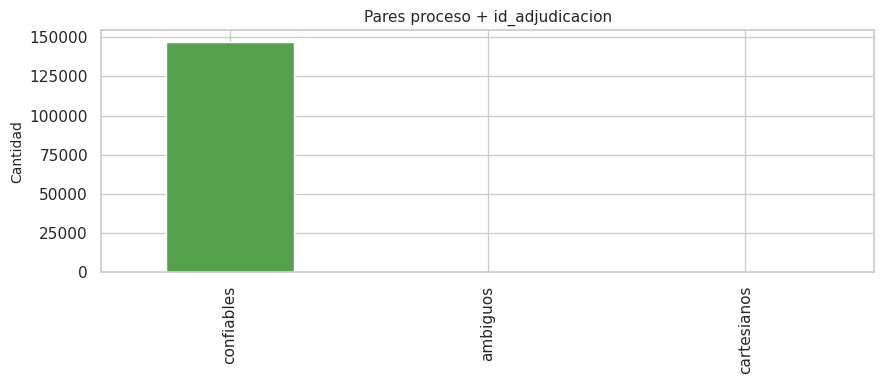

Salidas adjudicaciones: /home/jovyan/work/spark-apps/notebooks/salidas/2026-09/procesos/adjudicaciones


In [12]:
base = filas.copy()
base["_awd"] = base["id_adjudicacion"].astype(str).str.strip()
base.loc[awd_vacio, "_awd"] = "_sin_awd"
if "codigoproveedor" in base.columns:
    base["_prov"] = base["codigoproveedor"].astype(str).str.strip()
    mask_cod = vacio_txt(base["codigoproveedor"])
    if "nombre_del_proveedor" in base.columns:
        base.loc[mask_cod, "_prov"] = base.loc[mask_cod, "nombre_del_proveedor"].astype(str).str.strip()
elif "nombre_del_proveedor" in base.columns:
    base["_prov"] = base["nombre_del_proveedor"].astype(str).str.strip()
else:
    base["_prov"] = "_sin_proveedor"
base.loc[vacio_txt(base["_prov"]), "_prov"] = "_sin_proveedor"

pares = (
    base.groupby(["id_del_proceso", "_awd"], dropna=False)
    .agg(
        n_filas=("socrata_id", "count"),
        n_prov=("_prov", "nunique"),
        n_val=("valor_num", "nunique"),
        n_prov_nom=("nombre_del_proveedor", "nunique"),
    )
    .reset_index()
)
pares["cartesiano"] = (pares["n_prov"] >= 2) & (pares["n_val"] >= 2)
pares["sin_awd"] = pares["_awd"].eq("_sin_awd")
pares["ambiguo"] = pares["cartesiano"] | (pares["sin_awd"] & ((pares["n_prov"] > 1) | (pares["n_val"] > 1)))
pares["confiable"] = ~pares["ambiguo"] & ~pares["sin_awd"]

n_cart = int(pares["cartesiano"].sum())
n_amb = int(pares["ambiguo"].sum())
n_ok = int(pares["confiable"].sum())
proc_amb = pares.loc[pares["ambiguo"], "id_del_proceso"].nunique()

print("Pares proceso+adjudicación:", len(pares))
print("Confiables:", n_ok)
print("Ambiguos:", n_amb, "| cartesianos:", n_cart)
print("Procesos con algún par ambiguo:", proc_amb)

# No sumar valores en cartesianos: se reporta nunique, no suma.
val_ok = pares.loc[pares["confiable"]].merge(
    base[["id_del_proceso", "_awd", "valor_num"]].drop_duplicates(["id_del_proceso", "_awd", "valor_num"]),
    on=["id_del_proceso", "_awd"],
    how="left",
)
print("Valores en pares confiables (sin sumar cartesianos): n=", len(val_ok),
      "| mediana=", float(val_ok["valor_num"].median()) if val_ok["valor_num"].notna().any() else None)

ej_cart = pares.loc[pares["cartesiano"]].head(8)
display(ej_cart)
pares.loc[pares["ambiguo"]].to_csv(SAL_ADJ / "pares_ambiguos.csv", index=False)

res_adj = pd.DataFrame([{
    "filas_api": len(filas),
    "socrata_id": n_sid,
    "procesos": n_proc,
    "procesos_raw": n_raw,
    "pk_repetidas": int(len(dups)),
    "diff_proveedor_o_valor": n_195,
    "id_adjudicacion_distintos": n_awd,
    "proveedores_distintos": n_prov,
    "pares_confiables": n_ok,
    "pares_ambiguos": n_amb,
    "pares_cartesianos": n_cart,
    "suma_valores_cartesianos": "no aplicada",
}])
display(res_adj)
res_adj.to_csv(SAL_ADJ / "resumen_adjudicaciones.csv", index=False)

fig, ax = plt.subplots()
pd.Series({"confiables": n_ok, "ambiguos": n_amb, "cartesianos": n_cart}).plot(
    kind="bar", ax=ax, color=["#54A24B", "#E45756", "#F58518"]
)
ax.set_title("Pares proceso + id_adjudicacion")
ax.set_ylabel("Cantidad")
plt.tight_layout()
plt.savefig(SAL_ADJ / "pares_adjudicacion.png", dpi=120, bbox_inches="tight")
plt.show()
print("Salidas adjudicaciones:", SAL_ADJ)
